[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gianni04/option-pricing-python/blob/main/02_binomial_tree.ipynb)

# 2. Binomial tree (Cox-Ross-Rubinstein)

The price moves up by u or down by d at each step. Working backwards from expiry gives the
option price. With many steps the European price converges to Black-Scholes, and the tree can
also price **American** options (exercise allowed at any step).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [2]:
def bs_price(S, K, T, r, sigma, kind="call"):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if kind == "call":
        return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

In [3]:
def binomial(S, K, T, r, sigma, n, kind="call", american=False):
    dt = T / n
    u = np.exp(sigma * np.sqrt(dt))
    d = 1 / u
    p = (np.exp(r * dt) - d) / (u - d)          # risk-neutral probability of an up move
    disc = np.exp(-r * dt)

    ST = S * u ** np.arange(n, -1, -1) * d ** np.arange(0, n + 1)   # prices at expiry
    values = np.maximum(ST - K, 0) if kind == "call" else np.maximum(K - ST, 0)

    for step in range(n - 1, -1, -1):
        values = disc * (p * values[:-1] + (1 - p) * values[1:])
        if american:
            St = S * u ** np.arange(step, -1, -1) * d ** np.arange(0, step + 1)
            exercise = np.maximum(St - K, 0) if kind == "call" else np.maximum(K - St, 0)
            values = np.maximum(values, exercise)
    return values[0]

In [4]:
S, K, T, r, sigma = 100, 100, 1.0, 0.03, 0.20
bs_call = bs_price(S, K, T, r, sigma, "call")

print(f"Black-Scholes call: {bs_call:.4f}")
for n in [10, 50, 100, 500, 1000]:
    tree = binomial(S, K, T, r, sigma, n)
    print(f"tree with {n:4d} steps: {tree:.4f}   error {tree - bs_call:+.4f}")
assert abs(binomial(S, K, T, r, sigma, 1000) - bs_call) < 0.01

Black-Scholes call: 9.4134
tree with   10 steps: 9.2179   error -0.1956
tree with   50 steps: 9.3738   error -0.0396
tree with  100 steps: 9.3936   error -0.0198
tree with  500 steps: 9.4094   error -0.0040
tree with 1000 steps: 9.4114   error -0.0020


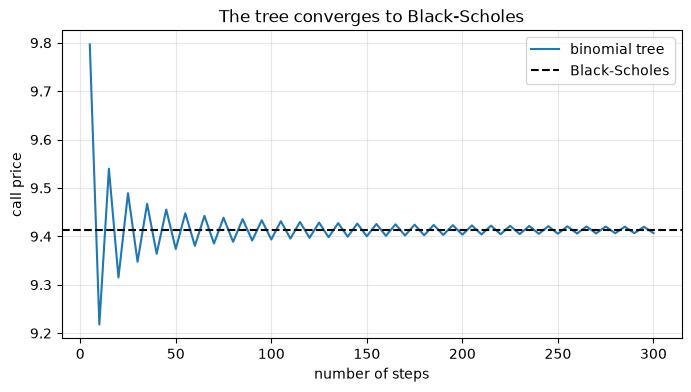

In [5]:
steps = np.arange(5, 301, 5)
prices = [binomial(S, K, T, r, sigma, n) for n in steps]
plt.figure(figsize=(8, 4))
plt.plot(steps, prices, label="binomial tree")
plt.axhline(bs_call, color="k", ls="--", label="Black-Scholes")
plt.xlabel("number of steps"); plt.ylabel("call price")
plt.title("The tree converges to Black-Scholes")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

**American vs European.** Without dividends an American call is never exercised early,
so it is worth the same as the European call. An American put can be worth more: when it is
deep in the money it is better to receive the strike now.

In [6]:
print("strike   European put   American put   early exercise premium")
for K_ in [80, 100, 120, 140]:
    eu = binomial(S, K_, T, r, sigma, 500, "put")
    am = binomial(S, K_, T, r, sigma, 500, "put", american=True)
    print(f"{K_:6d}   {eu:12.4f}   {am:12.4f}   {am - eu:10.4f}")

eu_c = binomial(S, K, T, r, sigma, 500, "call")
am_c = binomial(S, K, T, r, sigma, 500, "call", american=True)
print(f"\nATM call: European {eu_c:.4f}, American {am_c:.4f}")

strike   European put   American put   early exercise premium
    80         0.8607         0.8830       0.0223
   100         6.4540         6.7411       0.2871
   120        19.2195        20.6068       1.3873
   140        36.4932        40.0000       3.5068

ATM call: European 9.4094, American 9.4094
